In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/azizesseghaier/msd-brain-tumor-segmentation-validation-set/Val set/val labels/BRATS_482.nii
/kaggle/input/datasets/azizesseghaier/msd-brain-tumor-segmentation-validation-set/Val set/val labels/BRATS_437.nii
/kaggle/input/datasets/azizesseghaier/msd-brain-tumor-segmentation-validation-set/Val set/val labels/BRATS_438.nii
/kaggle/input/datasets/azizesseghaier/msd-brain-tumor-segmentation-validation-set/Val set/val labels/BRATS_411.nii
/kaggle/input/datasets/azizesseghaier/msd-brain-tumor-segmentation-validation-set/Val set/val labels/BRATS_461.nii
/kaggle/input/datasets/azizesseghaier/msd-brain-tumor-segmentation-validation-set/Val set/val labels/BRATS_413.nii
/kaggle/input/datasets/azizesseghaier/msd-brain-tumor-segmentation-validation-set/Val set/val labels/BRATS_480.nii
/kaggle/input/datasets/azizesseghaier/msd-brain-tumor-segmentation-validation-set/Val set/val labels/BRATS_440.nii
/kaggle/input/datasets/azizesseghaier/msd-brain-tumor-segmentation-validation-se

In [2]:
!git clone https://github.com/rsamodder/emcad-brain-tumor-segmentation.git
%cd emcad-brain-tumor-segmentation
!pip install -q timm einops nibabel
!bash scripts/setup.sh

Cloning into 'emcad-brain-tumor-segmentation'...
remote: Enumerating objects: 73, done.
remote: Counting objects: 100% (73/73), done.
remote: Compressing objects: 100% (68/68), done.
remote: Total 73 (delta 22), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (73/73), 628.32 KiB | 5.24 MiB/s, done.
Resolving deltas: 100% (22/22), done.
/kaggle/working/emcad-brain-tumor-segmentation
Cloning into 'EMCAD'...
remote: Enumerating objects: 267, done.
remote: Counting objects: 100% (93/93), done.
remote: Compressing objects: 100% (37/37), done.
remote: Total 267 (delta 73), reused 56 (delta 56), pack-reused 174 (from 1)
Receiving objects: 100% (267/267), 2.05 MiB | 11.11 MiB/s, done.
Resolving deltas: 100% (129/129), done.
-rw-r--r-- 1 root root 101501299 Dec  7  2021 pretrained_pth/pvt/pvt_v2_b2.pth


In [3]:
TR = "/kaggle/input/datasets/azizesseghaier/msd-brain-tumor-mri-training-set/Brain Tumor Training Set"
VA = "/kaggle/input/datasets/azizesseghaier/msd-brain-tumor-segmentation-validation-set/Val set"

!python -m src.preprocess --train_images "{TR}/training_images" --train_labels "{TR}/training_labels" \
    --val_images "{VA}/val images" --val_labels "{VA}/val labels" --out_dir data

done: data/train
done: data/val


In [4]:
!python train.py --data_dir data --epochs 1

train slices: 6540 | val slices: 2621
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/kaggle/working/emcad-brain-tumor-segmentation/EMCAD/lib/pvtv2.py:385: UserWarning: Overwriting pvt_v2_b0 in registry with lib.pvtv2.pvt_v2_b0. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  @register_model
/kaggle/working/emcad-brain-tumor-segmentation/EMCAD/lib/pvtv2.py:395: UserWarning: Overwriting pvt_v2_b1 in registry with lib.pvtv2.pvt_v2_b1.

In [5]:
!python train.py --data_dir data --epochs 15 --seed 0
!python evaluate.py --data_dir data --ckpt checkpoints/best.pth
!python visualize.py --data_dir data --ckpt checkpoints/best.pth

train slices: 6540 | val slices: 2621
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/kaggle/working/emcad-brain-tumor-segmentation/EMCAD/lib/pvtv2.py:385: UserWarning: Overwriting pvt_v2_b0 in registry with lib.pvtv2.pvt_v2_b0. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  @register_model
/kaggle/working/emcad-brain-tumor-segmentation/EMCAD/lib/pvtv2.py:395: UserWarning: Overwriting pvt_v2_b1 in registry with lib.pvtv2.pvt_v2_b1.

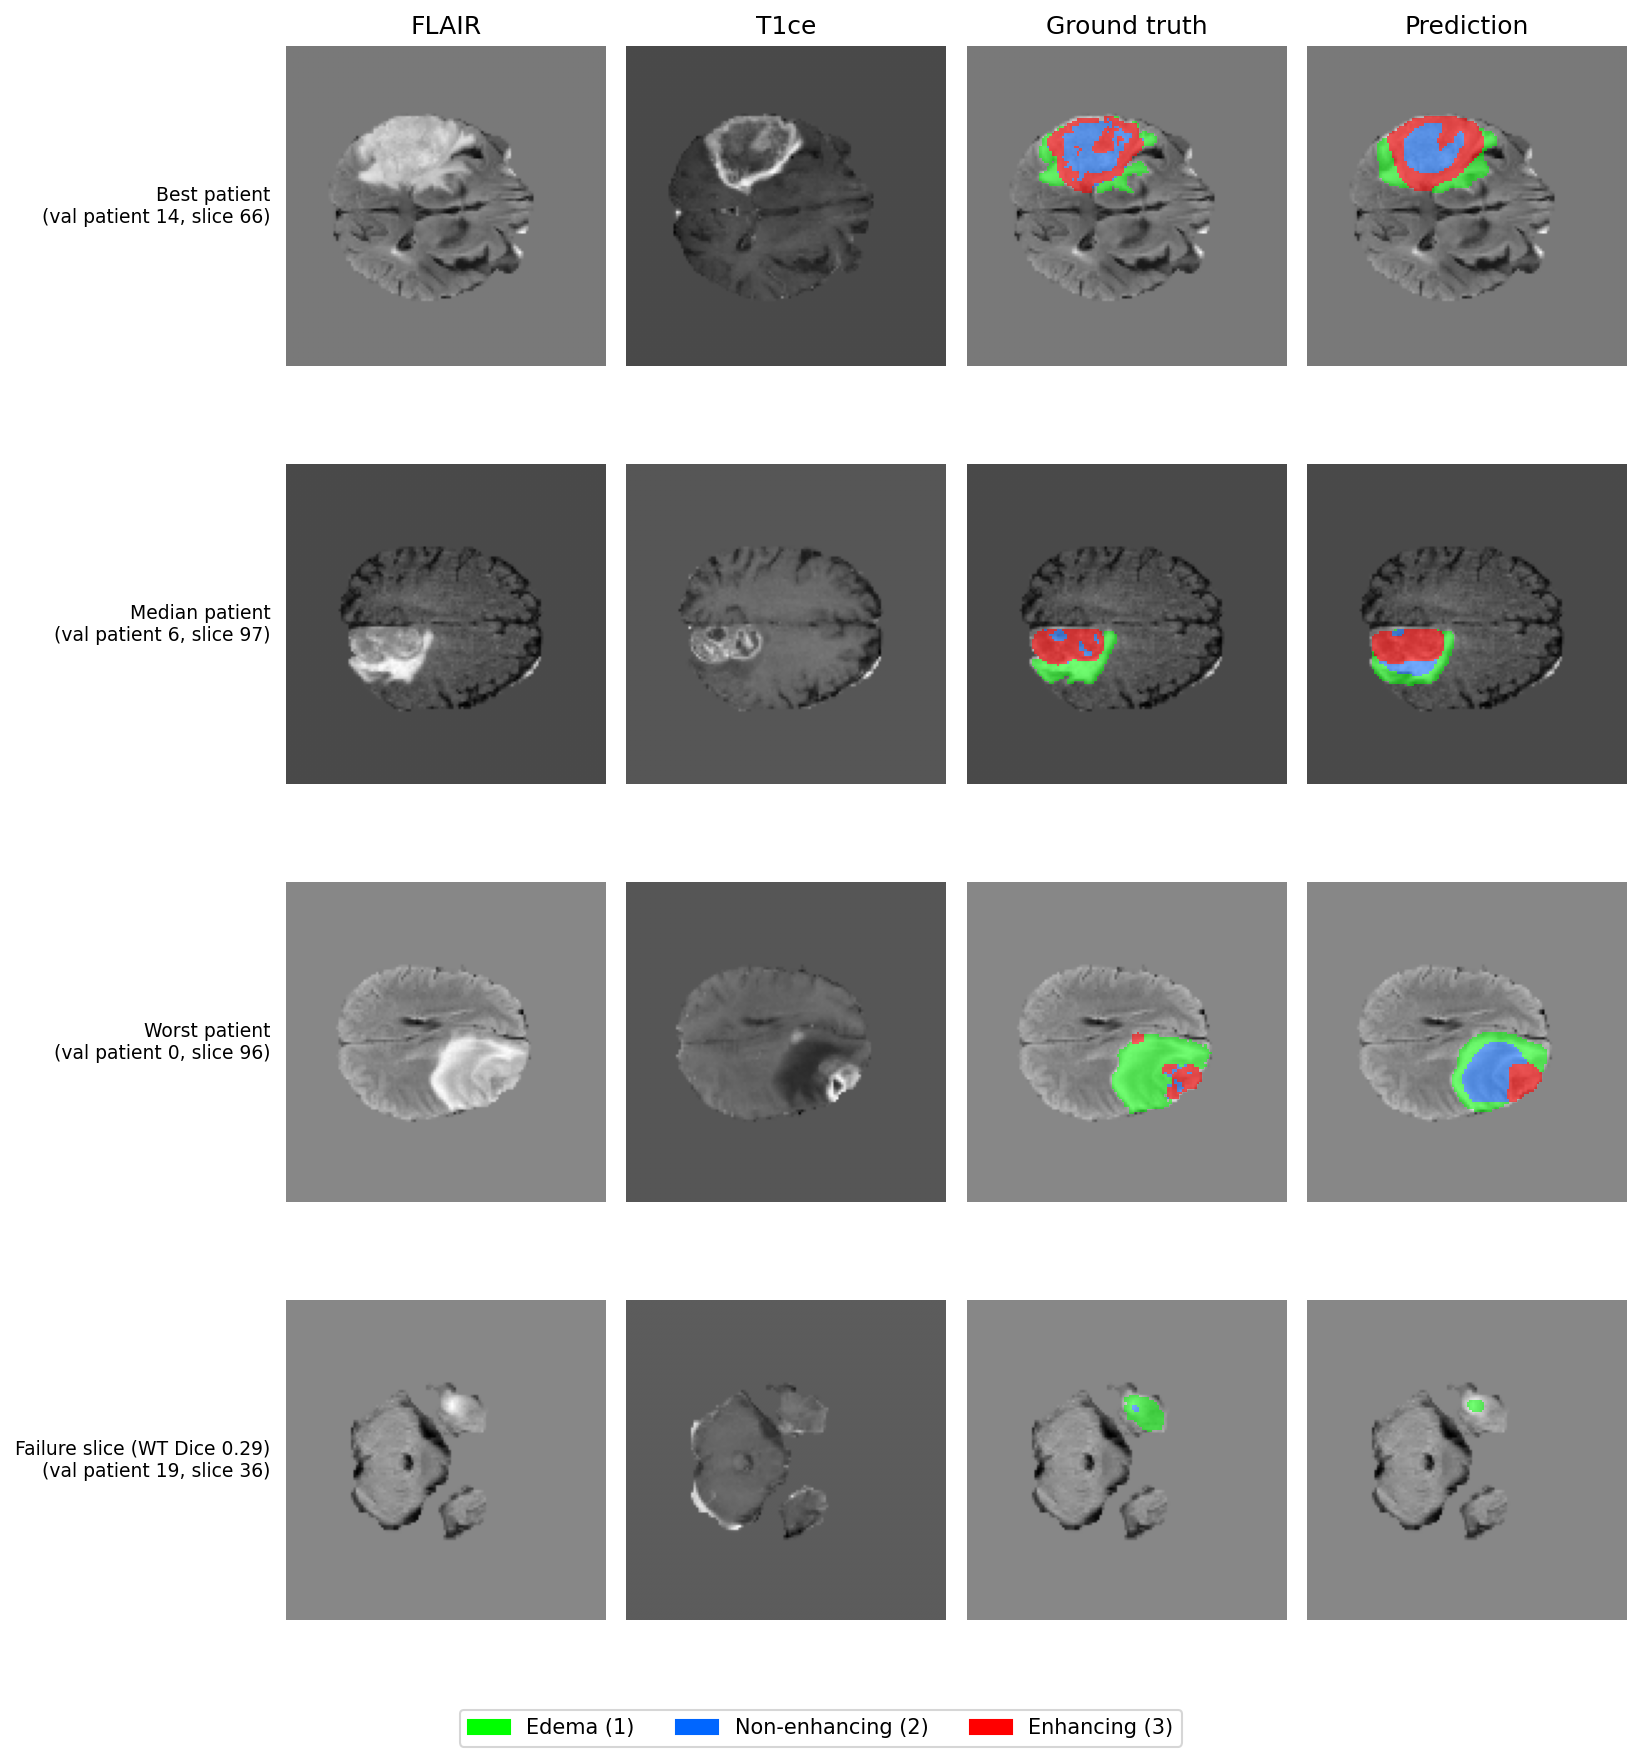

In [7]:
from IPython.display import Image
Image("results/overlays.png")